# Collaborative Filtering Movie Recommender

This notebook uses a tiny synthetic ratings matrix to show the core idea behind collaborative filtering: similar users are used to predict unseen movies. It is fully deterministic and runnable offline, making it a clear teaching example instead of a live recommendation service.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np

OUTPUT_DIR = Path('generated/recommender-031'); OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
ratings = np.array([
    [5, 4, 0, 3],
    [4, 5, 2, 0],
    [0, 3, 5, 4],
    [2, 0, 4, 5],
    [3, 2, 0, 4],
], dtype=float)
movies = ['Alpha', 'Beta', 'Gamma', 'Delta']
users = ['U1', 'U2', 'U3', 'U4', 'U5']
user_similarity = np.nan_to_num((ratings @ ratings.T) / (np.linalg.norm(ratings, axis=1)[:, None] * np.linalg.norm(ratings, axis=1)[None, :]), nan=0.0)
print(user_similarity)

[[1.         0.84327404 0.48       0.52704628 0.91914503]
 [0.84327404 1.         0.52704628 0.35555556 0.60900019]
 [0.48       0.52704628 1.         0.84327404 0.5777483 ]
 [0.52704628 0.35555556 0.84327404 1.         0.71972749]
 [0.91914503 0.60900019 0.5777483  0.71972749 1.        ]]


## 1. Estimate most similar users and suggest unseen titles

In [2]:
target_user = 0
scores = user_similarity[target_user] @ ratings / np.maximum((user_similarity[target_user] > 0).sum(), 1)
seen = ratings[target_user] > 0
recommendation_scores = np.where(seen, -np.inf, scores)
ranked = np.argsort(recommendation_scores)[::-1]
print('top recommendations for U1:', [(movies[i], recommendation_scores[i]) for i in ranked[:3]])

top recommendations for U1: [('Gamma', np.float64(1.2389466384404109)), ('Delta', np.float64(-inf)), ('Beta', np.float64(-inf))]


## 2. Visualize the recommendation scores

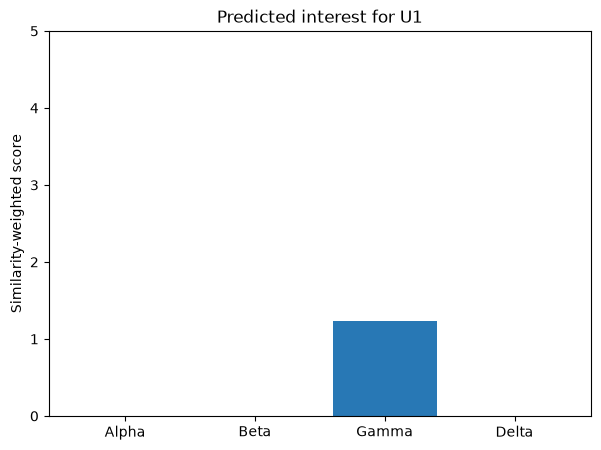

saved: generated\recommender-031\collaborative-filtering-recommendations.png


In [3]:
scores_for_plot = recommendation_scores.copy()
for idx in np.where(np.isneginf(scores_for_plot))[0]:
    scores_for_plot[idx] = 0.0
figure, ax = plt.subplots(figsize=(7, 5))
ax.bar(movies, scores_for_plot, color='#2878b5')
ax.set_title('Predicted interest for U1')
ax.set_ylabel('Similarity-weighted score')
ax.set_ylim(0, 5)
figure_path = OUTPUT_DIR / 'collaborative-filtering-recommendations.png'; figure.savefig(figure_path, dpi=170, bbox_inches='tight'); plt.show(); print('saved:', figure_path)